# 11. Vector calculus in Cartesian, cylindrical and spherical coordinates

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/11_vector_calculus.ipynb)

Transport phenomena, electromagnetics and fluid mechanics are written in terms of gradient,
divergence, curl and the Laplacian. In Cartesian coordinates these are easy. In cylindrical and
spherical coordinates most people look them up in a table at the back of the book, and hope
they copied the right line.

`sympy.vector` **derives** those tables. This notebook reproduces the entries you need most and
then uses them.

**Worked examples:** the Laplacian in three coordinate systems, a check that Poiseuille flow
satisfies the Navier–Stokes equation, heat conduction through a spherical shell, potential flow
around a cylinder, and the origin of the centripetal term.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from sympy.vector import CoordSys3D, curl, divergence, gradient

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 11.1 Cartesian coordinates

A coordinate system object carries the coordinates (`N.x`, `N.y`, `N.z`) and the unit vectors
(`N.i`, `N.j`, `N.k`).

In [2]:
N = CoordSys3D("N")

scalar_field = N.x**2 * N.y + sp.sin(N.z)
gradient(scalar_field)

                  ⎛   2⎞                      
(2⋅x_N⋅y_N) i_N + ⎝x_N ⎠ j_N  + (cos(z_N)) k_N

In [3]:
vector_field = N.x * N.y * N.i + N.y * N.z * N.j + N.z * N.x * N.k
divergence(vector_field), curl(vector_field)

(x_N + y_N + z_N, (-y_N) i_N + (-z_N) j_N + (-x_N) k_N)

Two identities hold for *any* smooth field. Using undefined functions proves them in general,
not just for one example.

In [4]:
f = sp.Function("f")(N.x, N.y, N.z)
Fx, Fy, Fz = (sp.Function(name)(N.x, N.y, N.z) for name in ("F_x", "F_y", "F_z"))
F = Fx * N.i + Fy * N.j + Fz * N.k

curl_of_gradient = curl(gradient(f))               # a gradient field has no rotation
divergence_of_curl = sp.simplify(divergence(curl(F)))   # a curl field has no sources
print("curl(grad f) =", curl_of_gradient, "    div(curl F) =", divergence_of_curl)
assert curl_of_gradient == sp.vector.Vector.zero and divergence_of_curl == 0

curl(grad f) = 0     div(curl F) = 0


## 11.2 Deriving the Laplacian in curvilinear coordinates

Create the coordinate system with a `transformation`, and the same functions account for the
changing directions of the unit vectors.

In [5]:
C = CoordSys3D("C", transformation="cylindrical", variable_names=("r", "theta", "z"))
S = CoordSys3D("S", transformation="spherical", variable_names=("r", "theta", "phi"))

r, theta, z, phi = sp.symbols("r theta z phi", positive=True)

def plain(expr, system):
    """Replace the system's coordinates by ordinary symbols, for readable output."""
    names = {"C": (r, theta, z), "S": (r, theta, phi)}[str(system)]
    return expr.subs(dict(zip(system.base_scalars(), names)))

In [6]:
f_cyl = sp.Function("f")(C.r, C.theta, C.z)
laplacian_cyl = sp.expand(sp.simplify(divergence(gradient(f_cyl))))
plain(laplacian_cyl, C)

                                                      2             
                                                     ∂              
                                    ∂                ───(f(r, θ, z))
 2                 2                ──(f(r, θ, z))     2            
∂                 ∂                 ∂r               ∂θ             
───(f(r, θ, z)) + ───(f(r, θ, z)) + ────────────── + ───────────────
  2                 2                     r                 2       
∂r                ∂z                                       r        

In [7]:
f_sph = sp.Function("f")(S.r, S.theta, S.phi)
laplacian_sph = sp.expand(sp.trigsimp(sp.expand(divergence(gradient(f_sph)))))
plain(laplacian_sph, S)

                                      2                                  2     ↪
                                     ∂                                  ∂      ↪
                    ∂                ───(f(r, θ, φ))   ∂                ───(f( ↪
 2                2⋅──(f(r, θ, φ))     2               ──(f(r, θ, φ))     2    ↪
∂                   ∂r               ∂θ                ∂θ               ∂φ     ↪
───(f(r, θ, φ)) + ──────────────── + ─────────────── + ────────────── + ────── ↪
  2                      r                  2             2                2   ↪
∂r                                         r             r ⋅tan(θ)        r ⋅s ↪

↪          
↪          
↪ r, θ, φ))
↪          
↪          
↪ ─────────
↪   2      
↪ in (θ)   

Here $\theta$ in the spherical system is the polar angle measured from the $z$ axis, the
physics convention. **Verify** against the compact textbook forms:

$$\nabla^2 f = \frac{1}{r}\frac{\partial}{\partial r}\!\left(r\frac{\partial f}{\partial r}\right)
+ \frac{1}{r^2}\frac{\partial^2 f}{\partial\theta^2} + \frac{\partial^2 f}{\partial z^2}
\quad\text{(cylindrical)}$$

$$\nabla^2 f = \frac{1}{r^2}\frac{\partial}{\partial r}\!\left(r^2\frac{\partial f}{\partial r}\right)
+ \frac{1}{r^2\sin\theta}\frac{\partial}{\partial\theta}\!\left(\sin\theta\frac{\partial f}{\partial\theta}\right)
+ \frac{1}{r^2\sin^2\theta}\frac{\partial^2 f}{\partial\phi^2}
\quad\text{(spherical)}$$

In [8]:
g = sp.Function("f")(r, theta, z)
textbook_cyl = sp.diff(r * sp.diff(g, r), r) / r + sp.diff(g, theta, 2) / r**2 + sp.diff(g, z, 2)
assert sp.simplify(plain(laplacian_cyl, C) - textbook_cyl) == 0

g = sp.Function("f")(r, theta, phi)
textbook_sph = (sp.diff(r**2 * sp.diff(g, r), r) / r**2
                + sp.diff(sp.sin(theta) * sp.diff(g, theta), theta) / (r**2 * sp.sin(theta))
                + sp.diff(g, phi, 2) / (r**2 * sp.sin(theta) ** 2))
assert sp.simplify(plain(laplacian_sph, S) - textbook_sph) == 0

## 11.3 Checking a solution: Poiseuille flow

**Problem.** Notebook 6 found the pipe-flow profile $u_z = \dfrac{G}{4\mu}(R^2 - r^2)$. Confirm
that it satisfies the axial Navier–Stokes equation $\mu\nabla^2 u_z = -G$ and the continuity
equation, and find the vorticity.

In [9]:
G, mu, R = sp.symbols("G mu R", positive=True)

u_z = G * (R**2 - C.r**2) / (4 * mu)
velocity = u_z * C.k

assert sp.simplify(mu * divergence(gradient(u_z)) + G) == 0      # momentum
assert divergence(velocity) == 0                                 # continuity (incompressible)

vorticity = curl(velocity)
plain(vorticity.dot(C.j), C)          # the only non-zero component is in the θ direction

G⋅r
───
2⋅μ

The vorticity grows linearly with $r$: fluid elements spin fastest at the wall, where the shear
is greatest, and not at all on the axis.

## 11.4 Heat conduction through a spherical shell

**Problem.** A hollow sphere has inner surface $r_1$ at $T_1$ and outer surface $r_2$ at $T_2$.
Find the steady temperature profile and the heat flow.

**By hand.** With spherical symmetry $T = T(r)$, so $\nabla^2 T = 0$ reduces to an ordinary
differential equation. Let SymPy do the reduction:

In [10]:
T = sp.Function("T")
conduction = plain(sp.simplify(divergence(gradient(T(S.r)))), S).doit()
conduction

              d       
 2          2⋅──(T(r))
d             dr      
───(T(r)) + ──────────
  2             r     
dr                    

In [11]:
r1, r2, T1, T2, k = sp.symbols("r_1 r_2 T_1 T_2 k", positive=True)

T_shell = sp.dsolve(conduction, T(r), ics={T(r1): T1, T(r2): T2}).rhs
heat_flow = sp.simplify(-k * 4 * sp.pi * r**2 * sp.diff(T_shell, r))      # Fourier's law × area
sp.simplify(T_shell), heat_flow

⎛r⋅(T₁⋅r₁ - T₂⋅r₂) + r₁⋅r₂⋅(-T₁ + T₂)  4⋅π⋅k⋅r₁⋅r₂⋅(-T₁ + T₂)⎞
⎜────────────────────────────────────, ──────────────────────⎟
⎝            r⋅(r₁ - r₂)                      r₁ - r₂        ⎠

In [12]:
# verify: the heat flow is the same through every spherical surface, and matches the textbook
assert not heat_flow.has(r)
assert sp.simplify(heat_flow - 4 * sp.pi * k * r1 * r2 * (T1 - T2) / (r2 - r1)) == 0

## 11.5 Potential flow around a cylinder

**Problem.** Uniform flow of speed $U$ past a cylinder of radius $a$ has the velocity potential

$$\phi = U\left(r + \frac{a^2}{r}\right)\cos\theta .$$

Check that it is a valid incompressible, irrotational flow, find the velocity on the surface,
and compute the pressure distribution and the drag.

In [13]:
U, a = sp.symbols("U a", positive=True)

potential = U * (C.r + a**2 / C.r) * sp.cos(C.theta)
assert sp.simplify(divergence(gradient(potential))) == 0          # Laplace's equation holds

flow = gradient(potential)
v_r = sp.simplify(flow.dot(C.i))
v_theta = sp.simplify(flow.dot(C.j))
plain(v_r, C), plain(v_theta, C)

⎛  ⎛   2    2⎞            ⎛ 2    2⎞        ⎞
⎜U⋅⎝- a  + r ⎠⋅cos(θ)  -U⋅⎝a  + r ⎠⋅sin(θ) ⎟
⎜────────────────────, ────────────────────⎟
⎜          2                     2         ⎟
⎝         r                     r          ⎠

In [14]:
# on the surface r = a: nothing flows through the wall, and the tangential speed is 2U sinθ
assert v_r.subs(C.r, a) == 0
surface_speed = plain(v_theta.subs(C.r, a), C)
surface_speed

-2⋅U⋅sin(θ)

The fluid passes the top and bottom of the cylinder at twice the free-stream speed.
Bernoulli's equation gives the pressure coefficient
$C_p = \dfrac{p - p_\infty}{\tfrac12\rho U^2} = 1 - \left(\dfrac{v}{U}\right)^2$ on the surface.

In [15]:
C_p = sp.simplify(1 - (surface_speed / U) ** 2)
drag = sp.integrate(C_p * sp.cos(theta), (theta, 0, 2 * sp.pi))       # pressure force along the flow
lift = sp.integrate(C_p * sp.sin(theta), (theta, 0, 2 * sp.pi))
assert drag == 0 and lift == 0
C_p, drag, lift

⎛         2         ⎞
⎝1 - 4⋅sin (θ), 0, 0⎠

**Zero drag.** This is d'Alembert's paradox: an ideal (inviscid) fluid exerts no net force on
the cylinder, because the pressure distribution is symmetric front to back. Real drag comes from
viscosity and flow separation, which potential flow leaves out.

The streamlines are contours of the stream function $\psi = U\left(r - \dfrac{a^2}{r}\right)\sin\theta$.

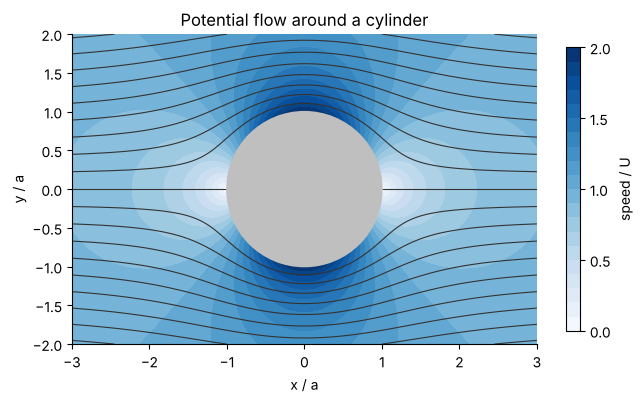

In [16]:
x, y = sp.symbols("x y", real=True)
radius = sp.sqrt(x**2 + y**2)
psi = (radius - 1 / radius) * y / radius            # U = a = 1; sinθ = y / r
speed = sp.sqrt(sum(sp.diff(psi, var) ** 2 for var in (x, y)))

psi_fun, speed_fun = (sp.lambdify((x, y), expr, "numpy") for expr in (psi, speed))
X, Y = np.meshgrid(np.linspace(-3, 3, 500), np.linspace(-2, 2, 400))
outside = X**2 + Y**2 >= 1

fig, ax = plt.subplots(figsize=(7.5, 4.6))
shade = ax.contourf(X, Y, np.where(outside, speed_fun(X, Y), np.nan), levels=np.linspace(0, 2, 21), cmap="Blues")
ax.contour(X, Y, np.where(outside, psi_fun(X, Y), np.nan), levels=np.linspace(-2, 2, 21), colors="0.2", linewidths=0.8, linestyles="solid")
ax.add_patch(plt.Circle((0, 0), 1, color="0.75", zorder=3))
ax.set(xlabel="x / a", ylabel="y / a", title="Potential flow around a cylinder", aspect="equal")
fig.colorbar(shade, ax=ax, label="speed / U", shrink=0.8, ticks=[0, 0.5, 1, 1.5, 2]);

The flow stagnates at the front and rear (lightest) and is fastest at the top and bottom
(darkest), as the formula $2U\sin\theta$ says.

## 11.6 Where the centripetal term comes from

The Navier–Stokes equations in cylindrical coordinates contain terms like $-u_\theta^2/r$ that
have no Cartesian counterpart. They arise because the unit vectors change direction from point
to point.

The convective acceleration is $(\mathbf{u}\cdot\nabla)\mathbf{u}$. The vector identity

$$(\mathbf{u}\cdot\nabla)\mathbf{u} = \nabla\!\left(\tfrac12\,\mathbf{u}\cdot\mathbf{u}\right) - \mathbf{u}\times(\nabla\times\mathbf{u})$$

expresses it with gradient and curl, both of which `sympy.vector` handles correctly in
curvilinear coordinates.

In [17]:
u_r, u_t, u_zz = (sp.Function(name)(C.r, C.theta, C.z) for name in ("u_r", "u_theta", "u_z"))
u = u_r * C.i + u_t * C.j + u_zz * C.k

acceleration = gradient(u.dot(u) / 2) - u.cross(curl(u))
radial = sp.expand(sp.simplify(acceleration.dot(C.i)))
plain(radial, C)

                                                                               ↪
                                                                   2           ↪
            ∂                              ∂                 uₜₕₑₜₐ (r, θ, z)  ↪
uᵣ(r, θ, z)⋅──(uᵣ(r, θ, z)) + u_z(r, θ, z)⋅──(uᵣ(r, θ, z)) - ────────────────  ↪
            ∂r                             ∂z                       r          ↪

↪                   ∂              
↪   uₜₕₑₜₐ(r, θ, z)⋅──(uᵣ(r, θ, z))
↪                   ∂θ             
↪ + ───────────────────────────────
↪                  r               

In [18]:
azimuthal = sp.expand(sp.simplify(acceleration.dot(C.j)))
plain(azimuthal, C)

                                                                               ↪
                                                                               ↪
            ∂                                  ∂                     uᵣ(r, θ,  ↪
uᵣ(r, θ, z)⋅──(uₜₕₑₜₐ(r, θ, z)) + u_z(r, θ, z)⋅──(uₜₕₑₜₐ(r, θ, z)) + ───────── ↪
            ∂r                                 ∂z                              ↪

↪                                      ∂                  
↪                      uₜₕₑₜₐ(r, θ, z)⋅──(uₜₕₑₜₐ(r, θ, z))
↪ z)⋅uₜₕₑₜₐ(r, θ, z)                   ∂θ                 
↪ ────────────────── + ───────────────────────────────────
↪     r                                 r                 

The radial component contains $-u_\theta^2/r$, the centripetal acceleration, and the
azimuthal component contains $+u_r u_\theta/r$, the Coriolis-like coupling. **Verify** against
the textbook table.

In [19]:
table_r = u_r * u_r.diff(C.r) + u_t / C.r * u_r.diff(C.theta) - u_t**2 / C.r + u_zz * u_r.diff(C.z)
table_t = u_r * u_t.diff(C.r) + u_t / C.r * u_t.diff(C.theta) + u_r * u_t / C.r + u_zz * u_t.diff(C.z)
assert sp.simplify(radial - table_r) == 0 and sp.simplify(azimuthal - table_t) == 0

## Exercises

1. Derive the divergence of a vector field in spherical coordinates and compare it with your
   textbook.
2. Repeat 11.4 for a long hollow cylinder. The heat flow per unit length should be
   $2\pi k (T_1 - T_2)/\ln(r_2/r_1)$.
3. Add a circulation $\Gamma$ to the cylinder flow: $\phi \to \phi + \dfrac{\Gamma}{2\pi}\theta$.
   Show that the drag integral is still zero but $\int_0^{2\pi} C_p\sin\theta\,d\theta = 2\Gamma/(Ua)$,
   which corresponds to a force of magnitude $\rho U\Gamma$ per unit length (the Kutta–Joukowski
   lift). Which way does it point for $\Gamma > 0$?
4. Show that the rigid-body rotation $\mathbf{u} = \Omega r\,\mathbf{e}_\theta$ has vorticity
   $2\Omega$, while the free vortex $\mathbf{u} = \dfrac{\Gamma}{2\pi r}\,\mathbf{e}_\theta$ has none.
5. For Couette flow between rotating cylinders, $u_\theta = Ar + B/r$, use the radial result
   of 11.6 to find the radial pressure gradient (steady flow, density $\rho$; the radial
   viscous term is zero).